In [25]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

 Load the CSV file and take a quick look at its contents

In [26]:

FILE_PATH = "Sample - Superstore.csv"

df = pd.read_csv(FILE_PATH, encoding="latin1")

print("\nDataset columns:", df.columns)

print('\nDataset first five record:',df.head)

print('\nDataset last five record:',df.tail)

print("Dataset size:", df.shape)

print("\nDataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nSummary of numeric columns:")
print(df.describe().T)


Dataset columns: Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

Dataset first five record: <bound method NDFrame.head of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
1          2  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
2          3  CA-2016-138688   6/12/2016   6/16/2016    Second Class   
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017 

 Clean the dates, remove duplicate rows, and add a few useful columns

In [27]:

for column in ["Order Date", "Ship Date"]:
    df[column] = pd.to_datetime(df[column], errors="coerce")

df = df.drop_duplicates().copy()

df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin"] = np.where(
    df["Sales"] != 0,
    df["Profit"] / df["Sales"],
    np.nan,
)

In [28]:
# Calculate key sales and customer metrics
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

kpis = {
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Profit Margin": total_profit / total_sales if total_sales else np.nan,
    "Unique Orders": df["Order ID"].nunique(),
    "Unique Customers": df["Customer ID"].nunique(),
    "Average Order Value": df.groupby("Order ID")["Sales"].sum().mean(),
}

print("\nKey performance indicators:")
for name, value in kpis.items():
    if name == "Profit Margin":
        print(f"{name}: {value:.2%}")
    else:
        print(f"{name}: {value:,.2f}")


Key performance indicators:
Total Sales: 2,297,200.86
Total Profit: 286,397.02
Profit Margin: 12.47%
Unique Orders: 5,009.00
Unique Customers: 793.00
Average Order Value: 458.61


 Summarize sales and profit by category, region, sub-category, and month

In [17]:
category = df.groupby("Category", as_index=False).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)

region = df.groupby("Region", as_index=False).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)

sub_category = df.groupby("Sub-Category", as_index=False).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)

monthly = df.groupby("Order Month", as_index=False).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)

print("\nCategory performance:")
print(category.sort_values("Sales", ascending=False))

print("\nRegion performance:")
print(region.sort_values("Sales", ascending=False))

print("\nFive sub-categories with the lowest profit:")
print(sub_category.nsmallest(5, "Profit"))

print("\nFive sub-categories with the highest profit:")
print(sub_category.nlargest(5, "Profit"))



Category performance:
          Category        Sales       Profit
2       Technology  836154.0330  145454.9481
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008

Region performance:
    Region        Sales       Profit
3     West  725457.8245  108418.4489
1     East  678781.2400   91522.7800
0  Central  501239.8908   39706.3625
2    South  391721.9050   46749.4303

Five sub-categories with the lowest profit:
   Sub-Category        Sales      Profit
16       Tables  206965.5320 -17725.4811
4     Bookcases  114879.9963  -3472.5560
15     Supplies   46673.5380  -1189.0995
8     Fasteners    3024.2800    949.5182
11     Machines  189238.6310   3384.7569

Five sub-categories with the highest profit:
   Sub-Category       Sales      Profit
6       Copiers  149528.030  55617.8249
13       Phones  330007.054  44515.7306
0   Accessories  167380.318  41936.6357
12        Paper   78479.206  34053.5693
3       Binders  203412.733  30221.7633


 Create charts to explore sales, profit, discounts, and correlations

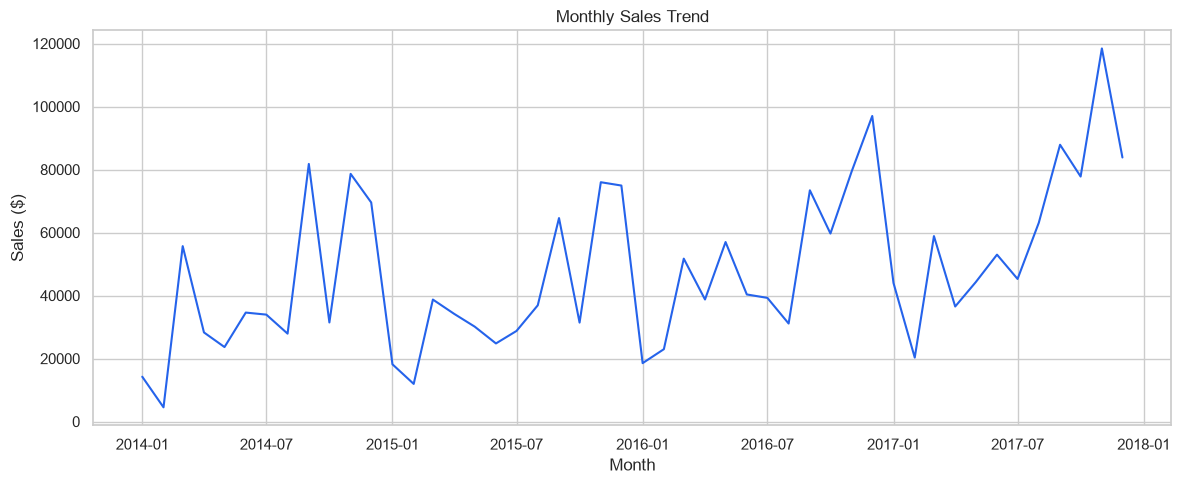

In [29]:
sns.set_theme(style="whitegrid")

# Monthly sales trend
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="Order Month", y="Sales", color="#2563EB")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

 Sales by category and profit by region

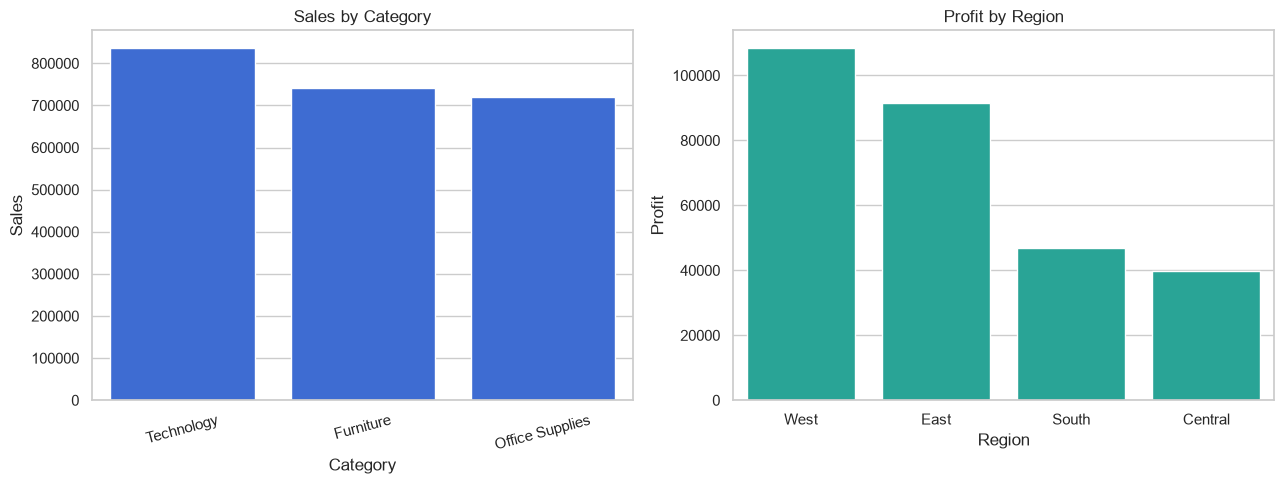

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=category.sort_values("Sales", ascending=False),
    x="Category",
    y="Sales",
    ax=axes[0],
    color="#2563EB",
)
axes[0].set_title("Sales by Category")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=region.sort_values("Profit", ascending=False),
    x="Region",
    y="Profit",
    ax=axes[1],
    color="#14B8A6",
)
axes[1].set_title("Profit by Region")

plt.tight_layout()
plt.show()

Profit by sub-category; use red for losses and teal for profits

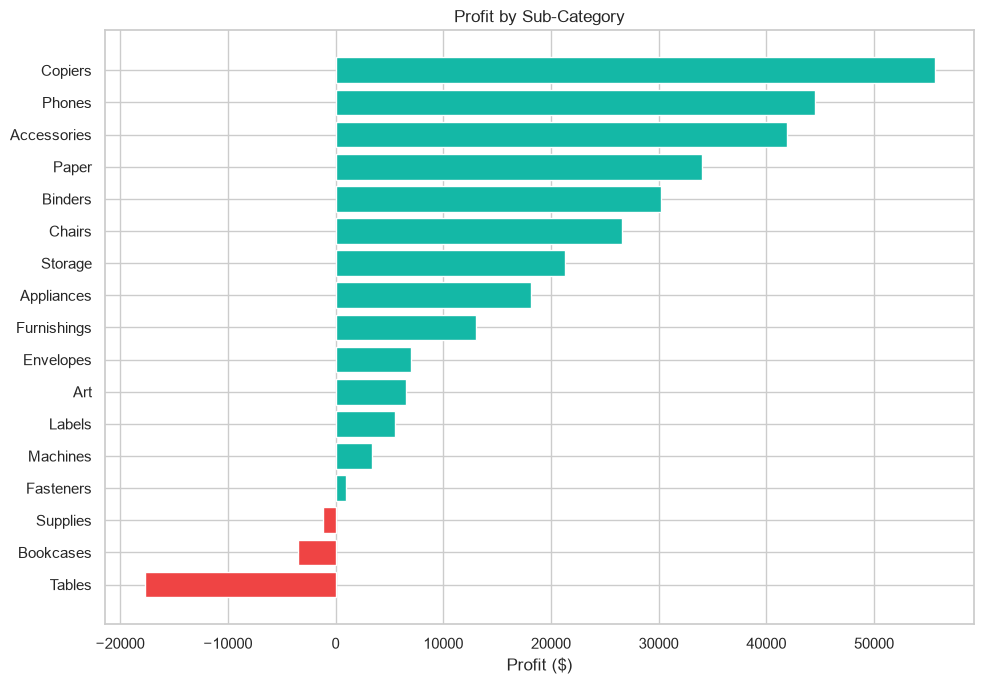

In [31]:

ordered = sub_category.sort_values("Profit")
colors = [
    "#EF4444" if profit < 0 else "#14B8A6"
    for profit in ordered["Profit"]
]

plt.figure(figsize=(10, 7))
plt.barh(ordered["Sub-Category"], ordered["Profit"], color=colors)
plt.title("Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.tight_layout()
plt.show()

 Compare discounts with profit

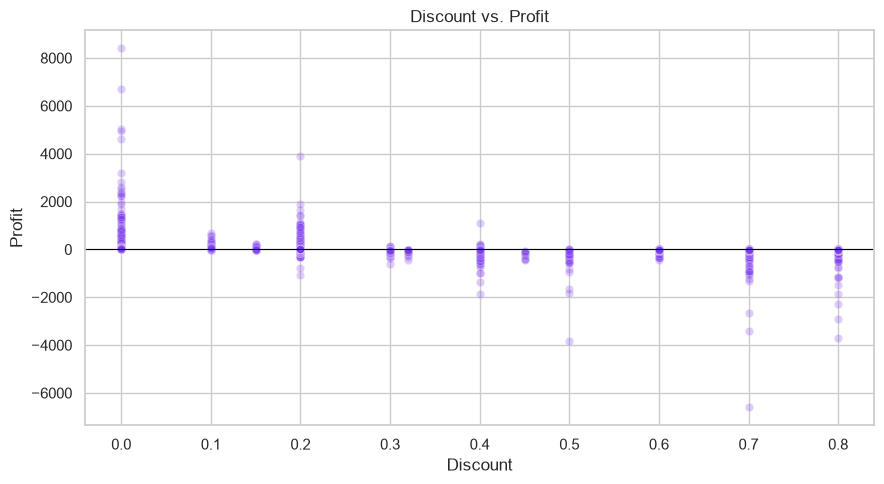

In [32]:

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.25,
    color="#7C3AED",
)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Discount vs. Profit")
plt.tight_layout()
plt.show()


 Show correlations between numeric columns

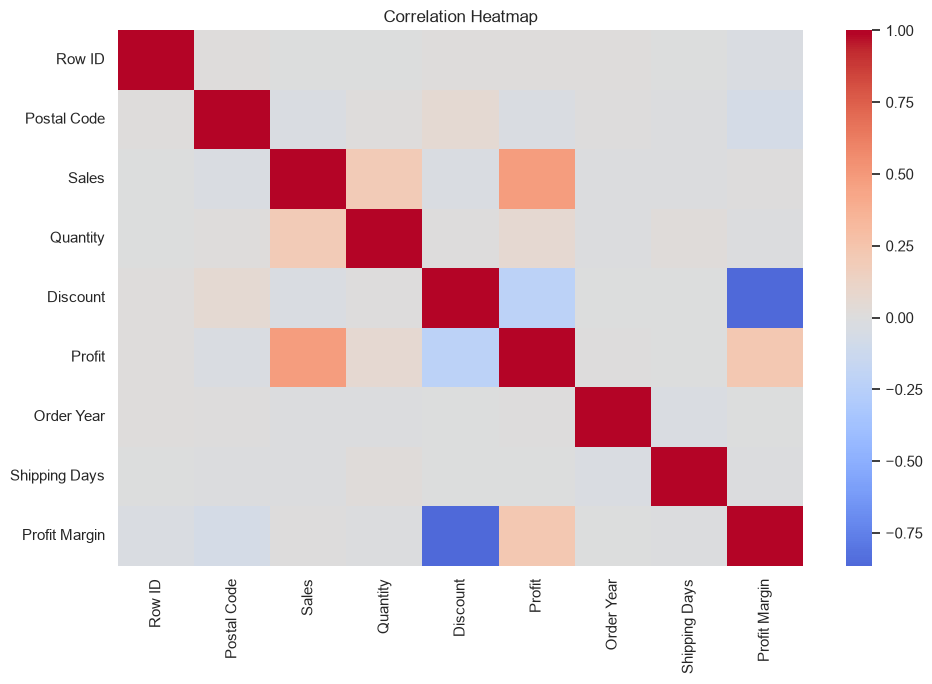

In [33]:
numeric = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [34]:
# Find unusually high or low values using the IQR method
def find_iqr_outliers(data, column):
    first_quartile = data[column].quantile(0.25)
    third_quartile = data[column].quantile(0.75)
    interquartile_range = third_quartile - first_quartile

    lower_limit = first_quartile - 1.5 * interquartile_range
    upper_limit = third_quartile + 1.5 * interquartile_range

    return data[
        (data[column] < lower_limit) | (data[column] > upper_limit)
    ]


sales_outliers = find_iqr_outliers(df, "Sales")
profit_outliers = find_iqr_outliers(df, "Profit")

print("\nNumber of sales outliers:", len(sales_outliers))
print("Number of profit outliers:", len(profit_outliers))


Number of sales outliers: 1167
Number of profit outliers: 1881


Save the cleaned data and summary tables as CSV files

In [35]:
df.to_csv("Superstore_Cleaned.csv", index=False)
category.to_csv("Category_Summary.csv", index=False)
region.to_csv("Region_Summary.csv", index=False)

print("\nAnalysis complete. The charts have been displayed and the CSV files are ready.")


Analysis complete. The charts have been displayed and the CSV files are ready.
